# Сравнение моделей SASRec и DreamRec.

Full-rank метрики (HR@K, NDCG@K) всех обученных моделей в одной таблице. Каждая модель
собирается по своему yaml через реестр `builders.MODELS`, веса берутся из чекпойнта,
сэмплинг идёт с параметрами из конфига этой модели — то есть ровно так, как её оценивал
тренер. Разброс в таблице считается по нескольким прогонам обучения и сидам сэмплинга,
как в `evaluate.py`; у SASRec сэмплинга нет, поэтому его разброс — только между прогонами.

Чтобы добавить или убрать модель — правь словарь `RUNS` ниже.

In [2]:
import os, random, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)                          # пути в yaml относительны корня проекта
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from builders import load_model_config
from data import build_dataloaders
from evaluate import evaluate, evaluate_runs
from train import seeded

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Корень проекта: {ROOT} | device: {device}')

Корень проекта: d:\Skoltech\Thesis\DiffText4Rec | device: cuda


## Какие чекпойнты сравнивать

`config` — yaml, с которым обучалась модель (из него берётся и тип модели, и параметры
сэмплинга), `ckpt` — папка с `best.pt` / `latest.pt`.

In [3]:
# ════════════════════════════════════════════════════════════
# КОНФИГ
# ════════════════════════════════════════════════════════════
RUNS = {
    'SASRec':         {'config': 'configs/atg/sasrec.yaml',           'ckpt': 'checkpoints/atg/sasrec'},
    'DreamRec':       {'config': 'configs/atg/dreamrec.yaml',         'ckpt': 'checkpoints/atg/dreamrec'},
    'DreamRecText':   {'config': 'configs/atg/dreamrec_text.yaml',    'ckpt': 'checkpoints/atg/dreamrec_text'},
    'DreamRecFMText': {'config': 'configs/atg/dreamrec_fm_text.yaml', 'ckpt': 'checkpoints/atg/dreamrec_fm_text'},
}

# Подписи и цвета на всех графиках ноутбука; ключ — имя модели из RUNS
# (iDreamRec есть только в результатах кода авторов)
LABELS = {
    'SASRec':            'SASRec',
    'DreamRec':          'Learned_DDPM',
    'DreamRecText':      'Frozen_DDPM',
    'DreamRecFMText':    'Frozen_FM',
    'DreamRecAlphaFuse': 'AlphaFuse_DDPM',
    'iDreamRec':         'iDreamRec',
}
COLORS = {
    'SASRec':            'tab:blue',
    'DreamRec':          'tab:orange',
    'DreamRecText':      'tab:green',
    'DreamRecFMText':    'tab:red',
    'DreamRecAlphaFuse': 'tab:purple',
    'iDreamRec':         'tab:brown',
}

TOP_K   = (10, 20)   # общие столбцы таблицы для всех моделей
N_CKPTS = 5          # прогонов обучения в таблице: best.pt из <имя конфига>_1 … _N_CKPTS
N_SEEDS = 5          # сидов сэмплинга 1 … N_SEEDS на каждый прогон

METRICS = [f'{prefix}@{k}' for k in TOP_K for prefix in ('HR', 'NDCG')]
N_ITEMS = load_model_config(next(iter(RUNS.values()))['config'])[1].data.n_items   # каталог общий


def random_row():
    """Аналитический бейзлайн: случайная перестановка каталога."""
    row = {}
    for k in TOP_K:
        row[f'HR@{k}']   = k / N_ITEMS
        row[f'NDCG@{k}'] = sum(1.0 / np.log2(r + 2) for r in range(k)) / N_ITEMS
    return row

## Сборка моделей и загрузка весов

In [3]:
# ════════════════════════════════════════════════════════════
# Модели, лоадеры и параметры сэмплинга
# ════════════════════════════════════════════════════════════
_loader_cache = {}

def loaders_for(cfg):
    """Лоадеры под конкретный конфиг: batch_size влияет на нарезку потока шума,
    поэтому у каждой модели он свой — тот же, что при её обучении."""
    key = (cfg.data.data_dir, cfg.data.batch_size, cfg.data.max_seq_len)
    if key not in _loader_cache:
        _loader_cache[key] = build_dataloaders(data_dir=cfg.data.data_dir, batch_size=cfg.data.batch_size,
                                               num_workers=0, seq_len=cfg.data.max_seq_len,
                                               splits=('val', 'test'))
    return _loader_cache[key]


models = {}
for name, run in RUNS.items():
    ckpt_path = Path(run['ckpt']) / 'best.pt'
    if not ckpt_path.exists():
        ckpt_path = Path(run['ckpt']) / 'latest.pt'
    if not ckpt_path.exists():
        print(f'{name:<15} пропущен: нет best.pt/latest.pt в {run["ckpt"]}')
        continue

    spec, cfg = load_model_config(run['config'])
    model = spec.build(cfg).to(device).eval()
    ckpt  = torch.load(ckpt_path, map_location='cpu', mmap=True)
    model.load_state_dict(ckpt['model_state'])

    models[name] = {
        'model':      model,
        'cfg':        cfg,
        'loaders':    loaders_for(cfg),
        'ckpt_dir':   Path(run['ckpt']),
        'num_steps':  cfg.eval.num_sample_steps or 1,      # SASRec не сэмплирует
        'w_cfg':      getattr(cfg.model, 'w_cfg', 0.0),
        'generative': cfg.model_type != 'sasrec',
        'ckpt_ndcg20': ckpt['metrics']['NDCG@20'],
    }
    print(f'{name:<15} {cfg.model_type:<17} эпоха {ckpt["epoch"]:<4} '
          f'params {model.param_summary()["total_trainable"]:>11,}  '
          f'шагов {models[name]["num_steps"]:<4} w_cfg {models[name]["w_cfg"]}  '
          f'val NDCG@20 в чекпойнте {models[name]["ckpt_ndcg20"]:.4f}')

print(f'\nЗагружено моделей: {len(models)}')

SASRec          sasrec            эпоха 50   params   1,627,520  шагов 1    w_cfg 0.0  val NDCG@20 в чекпойнте 0.0371
DreamRec        dreamrec          эпоха 250  params 142,095,616  шагов 50   w_cfg 0.0  val NDCG@20 в чекпойнте 0.0363
Item embeddings: (11924, 3072)
Loading whitening from cache: data\processed\whitening_cache_k3072_pc.npz
DreamRecText    dreamrec_text     эпоха 210  params 110,181,376  шагов 50   w_cfg 0.0  val NDCG@20 в чекпойнте 0.0348
Item embeddings: (11924, 3072)
Loading whitening from cache: data\processed\whitening_cache_k3072_pc.npz
DreamRecFMText  dreamrec_fm_text  эпоха 60   params 110,181,376  шагов 50   w_cfg 0.0  val NDCG@20 в чекпойнте 0.0358

Загружено моделей: 4


## Метрики

`evaluate_runs()` из `evaluate.py` — тот же протокол, что и `python src/evaluate.py --n-runs`:
для каждой модели берутся `best.pt` прогонов `<имя конфига>_1 … _N_CKPTS`, каждый
оценивается с сидами сэмплинга 1 … `N_SEEDS`, mean ± std — по всем `N_CKPTS × N_SEEDS`
запускам (std с n − 1). Ретривал — из конфига модели.

В проверочной таблице — val NDCG@20 каждого прогона: сохранённый тренером (сид 42) и среднее
по нашим сидам. Сильное расхождение значит, что конфиг не соответствует прогону.

In [4]:
# ════════════════════════════════════════════════════════════
# Оценка: N_CKPTS прогонов × N_SEEDS сидов сэмплинга на val и test
# ════════════════════════════════════════════════════════════
seeds   = list(range(1, N_SEEDS + 1))
reports = {}
results = {'val': {}, 'test': {}}      # split → модель → метрика → значения по всем запускам

for name, run in RUNS.items():
    print(f'--- {name} ---', flush=True)
    report = evaluate_runs(run['config'], n_runs=N_CKPTS, n_seeds=N_SEEDS, splits=('val', 'test'))
    reports[name] = report
    for split in ('val', 'test'):
        rows = report['results'][split]
        row  = report['retrieval_row'] or next(iter(rows))    # у SASRec строка одна — сама модель
        results[split][name] = {m: rows[row][m] for m in METRICS}

check = {}
for name, report in reports.items():
    vals = results['val'][name]['NDCG@20']                  # прогон за прогоном, по N_SEEDS на прогон
    for i, r in enumerate(report['runs']):
        check[(name, r['name'])] = {
            'эпоха': r['epoch'],
            'val NDCG@20 (чекпойнт, сид 42)': (r['saved_metrics'] or {}).get('NDCG@20', np.nan),
            f'val NDCG@20 (среднее по {N_SEEDS} сидам)': np.mean(vals[i * N_SEEDS:(i + 1) * N_SEEDS]),
        }
print()
print(pd.DataFrame(check).T.to_string(float_format=lambda x: f'{x:.4f}'))

--- SASRec ---
sasrec_1 (эпоха 60): готово
sasrec_2 (эпоха 80): готово
sasrec_3 (эпоха 70): готово
sasrec_4 (эпоха 100): готово
sasrec_5 (эпоха 100): готово
--- DreamRec ---
dreamrec_1 (эпоха 90): готово
dreamrec_2 (эпоха 240): готово
dreamrec_3 (эпоха 120): готово
dreamrec_4 (эпоха 100): готово
dreamrec_5 (эпоха 150): готово
--- DreamRecText ---
Item embeddings: (11924, 3072)
Loading whitening from cache: data\processed\whitening_cache_k3072_pc.npz
dreamrec_text_1 (эпоха 100): готово
dreamrec_text_2 (эпоха 120): готово
dreamrec_text_3 (эпоха 170): готово
dreamrec_text_4 (эпоха 140): готово
dreamrec_text_5 (эпоха 70): готово
--- DreamRecFMText ---
Item embeddings: (11924, 3072)
Loading whitening from cache: data\processed\whitening_cache_k3072_pc.npz
dreamrec_fm_text_1 (эпоха 130): готово
dreamrec_fm_text_2 (эпоха 150): готово
dreamrec_fm_text_3 (эпоха 140): готово
dreamrec_fm_text_4 (эпоха 90): готово
dreamrec_fm_text_5 (эпоха 70): готово

                                     эпоха  v

In [1]:
def mean_std_table(split):
    """Строки — модели, ячейки — 'mean ± std' по всем N_CKPTS × N_SEEDS запускам (std с n − 1, как в evaluate.py)."""
    rows = {name: {m: f'{np.mean(vals[m]):.4f} ± {np.std(vals[m], ddof=1):.4f}' for m in METRICS}
            for name, vals in results[split].items()}
    rows['Random'] = {m: f'{v:.4f}' for m, v in random_row().items()}
    df = pd.DataFrame(rows).T[METRICS]
    df.index.name = 'Model'
    return df


for split in ('val', 'test'):
    print(f'=== {split.upper()} (mean ± std по {N_CKPTS} прогонам × {N_SEEDS} сидов сэмплинга) ===')
    print(mean_std_table(split).to_string())
    print()

NameError: name 'N_CKPTS' is not defined

## Сравнение моделей на графике

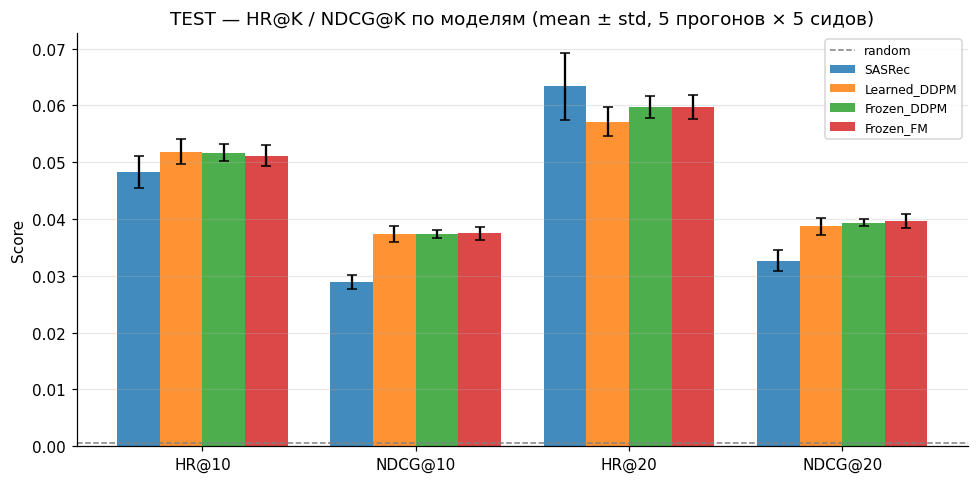

In [6]:
# ════════════════════════════════════════════════════════════
# Столбчатая диаграмма: test
# ════════════════════════════════════════════════════════════
def plot_test_bars():
    """Test-метрики всех моделей из results (mean ± std по N_CKPTS × N_SEEDS запускам)."""
    names = list(results['test'])
    x     = np.arange(len(METRICS))
    width = 0.8 / max(len(names), 1)

    fig, ax = plt.subplots(figsize=(9, 4.5))
    for i, name in enumerate(names):
        vals = [np.mean(results['test'][name][m])         for m in METRICS]
        errs = [np.std(results['test'][name][m], ddof=1)  for m in METRICS]
        ax.bar(x + i * width, vals, width, yerr=errs, capsize=3,
               color=COLORS.get(name), label=LABELS.get(name, name), alpha=0.85)
    ax.axhline(random_row()['NDCG@20'], color='gray', ls='--', lw=1, label='random')
    ax.set_xticks(x + width * (len(names) - 1) / 2); ax.set_xticklabels(METRICS)
    ax.set_ylabel('Score'); ax.grid(axis='y', alpha=0.3); ax.legend(fontsize=8)
    ax.set_title(f'TEST — HR@K / NDCG@K по моделям (mean ± std, {N_CKPTS} прогонов × {N_SEEDS} сидов)')
    plt.tight_layout(); plt.show()


plot_test_bars()

## Досчёт DreamRecAlphaFuse

Считается тем же протоколом (`evaluate_runs`, `N_CKPTS` прогонов × `N_SEEDS` сидов) и
дописывается в уже готовые `results`, поэтому ячейку с оценкой остальных моделей
перезапускать не нужно. Ниже — общая таблица и диаграмма по всем моделям.

--- DreamRecAlphaFuse ---
Item embeddings: (11924, 3072)
Loading whitening from cache: data\processed\whitening_cache_k3072_pc.npz
dreamrec_alphafuse_1 (эпоха 120): готово
dreamrec_alphafuse_2 (эпоха 80): готово
dreamrec_alphafuse_3 (эпоха 140): готово
dreamrec_alphafuse_4 (эпоха 90): готово
dreamrec_alphafuse_5 (эпоха 150): готово
                        эпоха  val NDCG@20 (чекпойнт, сид 42)  val NDCG@20 (среднее по 5 сидам)
dreamrec_alphafuse_1 120.0000                          0.0363                            0.0359
dreamrec_alphafuse_2  80.0000                          0.0362                            0.0365
dreamrec_alphafuse_3 140.0000                          0.0339                            0.0332
dreamrec_alphafuse_4  90.0000                          0.0368                            0.0353
dreamrec_alphafuse_5 150.0000                          0.0333                            0.0336

=== VAL (mean ± std по 5 прогонам × 5 сидов сэмплинга) ===
                             H

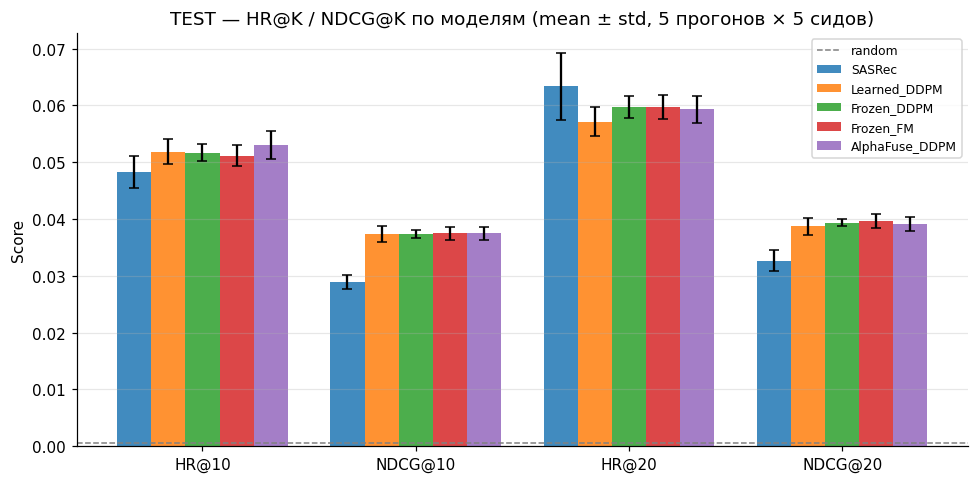

In [7]:
# ════════════════════════════════════════════════════════════
# DreamRecAlphaFuse: оценка и добавление к results
# ════════════════════════════════════════════════════════════
EXTRA_RUNS = {
    'DreamRecAlphaFuse': {'config': 'configs/atg/dreamrec_alphafuse.yaml', 'ckpt': 'checkpoints/atg/dreamrec_alphafuse'},
}

for name, run in EXTRA_RUNS.items():
    print(f'--- {name} ---', flush=True)
    report = evaluate_runs(run['config'], n_runs=N_CKPTS, n_seeds=N_SEEDS, splits=('val', 'test'))
    reports[name] = report
    RUNS[name]    = run
    for split in ('val', 'test'):
        rows = report['results'][split]
        row  = report['retrieval_row'] or next(iter(rows))
        results[split][name] = {m: rows[row][m] for m in METRICS}

    vals = results['val'][name]['NDCG@20']                  # прогон за прогоном, по N_SEEDS на прогон
    check = {r['name']: {'эпоха': r['epoch'],
                         'val NDCG@20 (чекпойнт, сид 42)': (r['saved_metrics'] or {}).get('NDCG@20', np.nan),
                         f'val NDCG@20 (среднее по {N_SEEDS} сидам)': np.mean(vals[i * N_SEEDS:(i + 1) * N_SEEDS])}
             for i, r in enumerate(report['runs'])}
    print(pd.DataFrame(check).T.to_string(float_format=lambda x: f'{x:.4f}'))

print()
for split in ('val', 'test'):
    print(f'=== {split.upper()} (mean ± std по {N_CKPTS} прогонам × {N_SEEDS} сидов сэмплинга) ===')
    print(mean_std_table(split).to_string())
    print()

plot_test_bars()

## Наши прогоны против кода авторов

Test-метрики, mean ± std. Числа вписаны вручную, поэтому ячейка не зависит от расчётов выше
(нужна только ячейка конфига — оттуда `LABELS` и `COLORS`): «наши» — из таблицы выше
(5 прогонов × 5 сидов сэмплинга), «авторы» — прогон кода из статей. Подписи и цвета те же,
что на остальных графиках ноутбука.

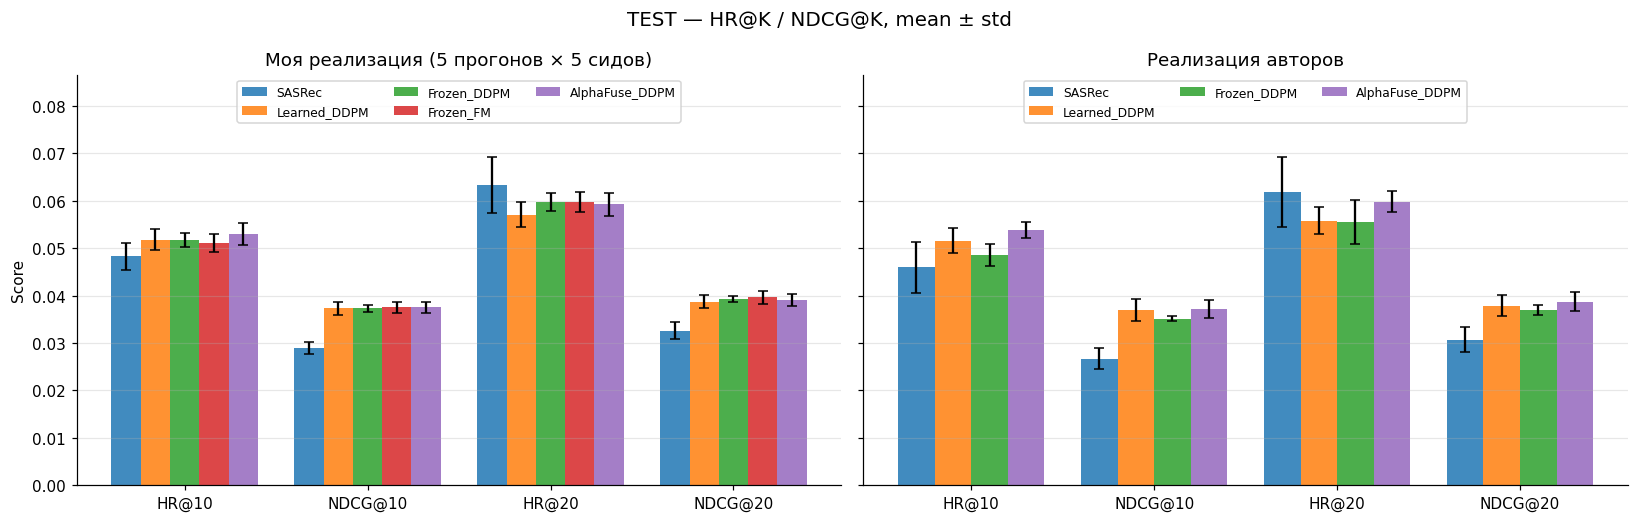

In [9]:
# ════════════════════════════════════════════════════════════
# Наши результаты и код авторов: две панели с общей осью Y (test, mean ± std)
# ════════════════════════════════════════════════════════════
CMP_METRICS = ['HR@10', 'NDCG@10', 'HR@20', 'NDCG@20']

# модель (ключ LABELS / COLORS) → метрика → (mean, std)
OURS = {
    'SASRec':            {'HR@10': (0.0483, 0.0028), 'NDCG@10': (0.0289, 0.0013), 'HR@20': (0.0633, 0.0059), 'NDCG@20': (0.0326, 0.0018)},
    'DreamRec':          {'HR@10': (0.0518, 0.0022), 'NDCG@10': (0.0373, 0.0014), 'HR@20': (0.0571, 0.0026), 'NDCG@20': (0.0387, 0.0014)},
    'DreamRecText':      {'HR@10': (0.0517, 0.0015), 'NDCG@10': (0.0373, 0.0007), 'HR@20': (0.0597, 0.0019), 'NDCG@20': (0.0393, 0.0006)},
    'DreamRecFMText':    {'HR@10': (0.0511, 0.0019), 'NDCG@10': (0.0375, 0.0012), 'HR@20': (0.0597, 0.0021), 'NDCG@20': (0.0396, 0.0013)},
    'DreamRecAlphaFuse': {'HR@10': (0.0530, 0.0024), 'NDCG@10': (0.0375, 0.0011), 'HR@20': (0.0593, 0.0024), 'NDCG@20': (0.0391, 0.0012)},
}

AUTHORS = {
    'SASRec':            {'HR@10': (0.0460, 0.0054), 'NDCG@10': (0.0267, 0.0023), 'HR@20': (0.0619, 0.0074), 'NDCG@20': (0.0307, 0.0027)},
    'DreamRec':          {'HR@10': (0.0516, 0.0026), 'NDCG@10': (0.0369, 0.0023), 'HR@20': (0.0558, 0.0029), 'NDCG@20': (0.0379, 0.0023)},
    'DreamRecText':         {'HR@10': (0.0485, 0.0023), 'NDCG@10': (0.0351, 0.0005), 'HR@20': (0.0555, 0.0047), 'NDCG@20': (0.0369, 0.0011)},
    'DreamRecAlphaFuse': {'HR@10': (0.0539, 0.0017), 'NDCG@10': (0.0372, 0.0019), 'HR@20': (0.0598, 0.0022), 'NDCG@20': (0.0387, 0.0020)},
}


def _bars(ax, table, title):
    x     = np.arange(len(CMP_METRICS))
    width = 0.8 / len(table)
    for i, (name, row) in enumerate(table.items()):
        means = [row[m][0] for m in CMP_METRICS]
        stds  = [row[m][1] for m in CMP_METRICS]
        ax.bar(x + i * width, means, width, yerr=stds, capsize=3,
               color=COLORS.get(name), label=LABELS.get(name, name), alpha=0.85)
    ax.set_xticks(x + width * (len(table) - 1) / 2); ax.set_xticklabels(CMP_METRICS)
    ax.set_title(title); ax.grid(axis='y', alpha=0.3)
    ax.legend(fontsize=8, loc='upper center', ncol=3)


# Верх оси с запасом под легенду над столбиками
_top = max(m + s for table in (OURS, AUTHORS) for row in table.values() for m, s in row.values())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
_bars(axes[0], OURS,    'Моя реализация (5 прогонов × 5 сидов)')
_bars(axes[1], AUTHORS, 'Реализация авторов')
axes[0].set_ylabel('Score'); axes[0].set_ylim(0, _top * 1.25)
plt.suptitle('TEST — HR@K / NDCG@K, mean ± std', fontsize=13)
plt.tight_layout(); plt.show()

## Кривые обучения

`log_val.csv` из папки каждого чекпойнта. Точки стоят реже, чем эпохи: валидация идёт
раз в `eval.every_epochs` эпох.

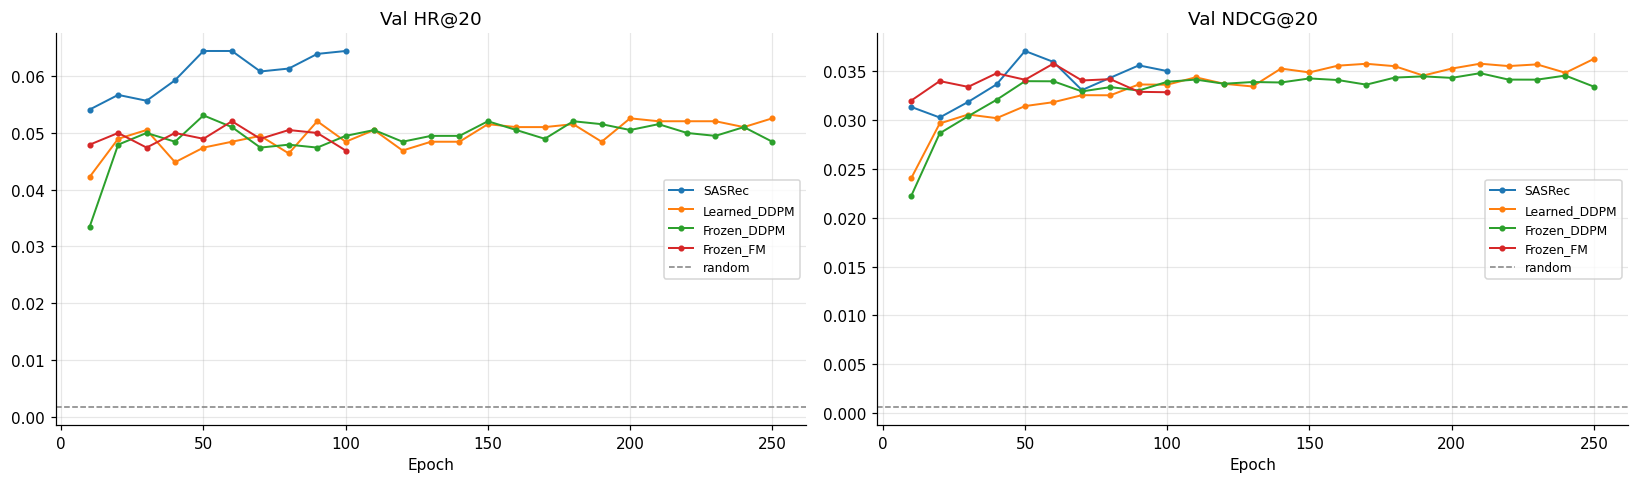

In [8]:
# ════════════════════════════════════════════════════════════
# Val HR@20 и NDCG@20 по эпохам
# ════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for name, entry in models.items():
    log_path = entry['ckpt_dir'] / 'log_val.csv'
    if not log_path.exists():
        print(f'{name}: нет {log_path}')
        continue
    log = pd.read_csv(log_path, comment='#')
    log = log[log['epoch'].astype(str) != 'test'].apply(pd.to_numeric, errors='coerce')
    axes[0].plot(log['epoch'], log['HR@20'],   'o-', ms=3, lw=1.3, color=COLORS.get(name), label=LABELS.get(name, name))
    axes[1].plot(log['epoch'], log['NDCG@20'], 'o-', ms=3, lw=1.3, color=COLORS.get(name), label=LABELS.get(name, name))

for ax, title, rnd in [(axes[0], 'Val HR@20', random_row()['HR@20']),
                       (axes[1], 'Val NDCG@20', random_row()['NDCG@20'])]:
    ax.axhline(rnd, color='gray', ls='--', lw=1, label='random')
    ax.set_xlabel('Epoch'); ax.set_title(title); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## NDCG@20 против числа шагов сэмплинга

Сколько шагов реально нужно генеративным моделям. У DDPM это respaced ancestral sampling —
тот же стохастический reverse-процесс по равномерно прорежённой сетке из `num_steps`
таймстепов (при `num_steps ≥ T` — полная цепочка); у Flow Matching — число шагов Euler ODE.
SASRec не участвует: сэмплинга у него нет.

Протокол как в таблице: прогоны `<имя конфига>_1 … _STEP_CKPTS`, сиды сэмплинга
1 … `STEP_SEEDS`, mean ± std по всем запускам. Стоимость линейна по
`STEP_CKPTS × STEP_SEEDS × сумма шагов` — если долго, уменьшай `STEP_SEEDS` или `STEP_LIST`.

In [8]:
# ════════════════════════════════════════════════════════════
# Свип по числу шагов сэмплинга: STEP_CKPTS прогонов × STEP_SEEDS сидов на точку
# ════════════════════════════════════════════════════════════
STEP_LIST  = [1, 5, 10, 25, 50, 100]
STEP_SPLIT = 'test'
STEP_CKPTS = N_CKPTS                 # прогоны <имя конфига>_1 … _STEP_CKPTS, как в таблице
STEP_SEEDS = N_SEEDS                 # сиды сэмплинга 1 … STEP_SEEDS на каждый прогон

curves = {}
for name, run in RUNS.items():
    spec, cfg = load_model_config(run['config'])
    if cfg.model_type == 'sasrec':
        continue                     # SASRec не сэмплирует
    net    = spec.build(cfg).to(device).eval()
    loader = loaders_for(cfg)[STEP_SPLIT]
    w_cfg  = getattr(cfg.model, 'w_cfg', 0.0)
    prefix = Path(run['config']).stem
    vals   = {steps: [] for steps in STEP_LIST}      # шаги → NDCG@20 по всем прогонам × сидам

    for i in range(1, STEP_CKPTS + 1):
        ckpt = torch.load(Path(cfg.output.dir) / f'{prefix}_{i}' / 'best.pt', map_location='cpu', mmap=True)
        net.load_state_dict(ckpt['model_state'])
        del ckpt
        for steps in STEP_LIST:
            for seed in range(1, STEP_SEEDS + 1):
                with seeded(seed, device):
                    vals[steps].append(evaluate(model=net, dataloader=loader, top_k_values=TOP_K,
                                                num_sample_steps=steps, w_cfg=w_cfg, device=device,
                                                show_progress=False)['NDCG@20'])
        print(f'{LABELS.get(name, name):<15} {prefix}_{i}: готово', flush=True)

    means = np.array([np.mean(vals[s])         for s in STEP_LIST])
    stds  = np.array([np.std(vals[s], ddof=1)  for s in STEP_LIST])
    curves[name] = (means, stds)
    for steps, m, s in zip(STEP_LIST, means, stds):
        print(f'{LABELS.get(name, name):<15} steps={steps:<4} NDCG@20 = {m:.4f} ± {s:.4f}')

    del net                          # на GPU держим только одну модель свипа за раз
    torch.cuda.empty_cache()

Learned_DDPM    dreamrec_1: готово
Learned_DDPM    dreamrec_2: готово
Learned_DDPM    dreamrec_3: готово
Learned_DDPM    dreamrec_4: готово
Learned_DDPM    dreamrec_5: готово
Learned_DDPM    steps=1    NDCG@20 = 0.0348 ± 0.0017
Learned_DDPM    steps=5    NDCG@20 = 0.0384 ± 0.0012
Learned_DDPM    steps=10   NDCG@20 = 0.0387 ± 0.0011
Learned_DDPM    steps=25   NDCG@20 = 0.0388 ± 0.0013
Learned_DDPM    steps=50   NDCG@20 = 0.0387 ± 0.0015
Learned_DDPM    steps=100  NDCG@20 = 0.0387 ± 0.0014
Item embeddings: (11924, 3072)
Loading whitening from cache: data\processed\whitening_cache_k3072_pc.npz
Frozen_DDPM     dreamrec_text_1: готово
Frozen_DDPM     dreamrec_text_2: готово
Frozen_DDPM     dreamrec_text_3: готово
Frozen_DDPM     dreamrec_text_4: готово
Frozen_DDPM     dreamrec_text_5: готово
Frozen_DDPM     steps=1    NDCG@20 = 0.0370 ± 0.0009
Frozen_DDPM     steps=5    NDCG@20 = 0.0394 ± 0.0005
Frozen_DDPM     steps=10   NDCG@20 = 0.0397 ± 0.0006
Frozen_DDPM     steps=25   NDCG@20 = 0.0395

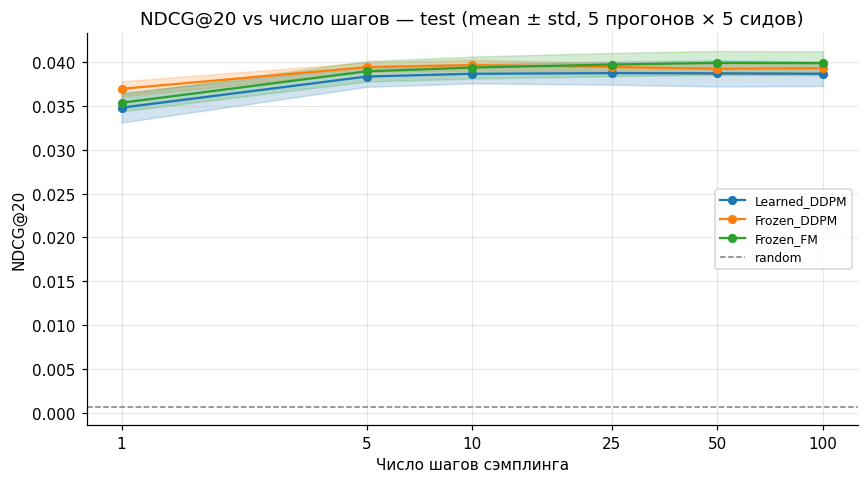

In [7]:
# ════════════════════════════════════════════════════════════
# График свипа (отдельно от расчёта: перерисовка не пересчитывает curves)
# ════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, (means, stds) in curves.items():
    line, = ax.plot(STEP_LIST, means, 'o-', lw=1.5, ms=5, color=COLORS.get(name), label=LABELS.get(name, name))
    ax.fill_between(STEP_LIST, means - stds, means + stds, color=line.get_color(), alpha=0.2)
ax.axhline(random_row()['NDCG@20'], color='gray', ls='--', lw=1, label='random')
ax.set_xscale('log'); ax.set_xticks(STEP_LIST); ax.set_xticklabels(STEP_LIST); ax.minorticks_off()
ax.set_xlabel('Число шагов сэмплинга'); ax.set_ylabel('NDCG@20')
ax.set_title(f'NDCG@20 vs число шагов — {STEP_SPLIT} '
             f'(mean ± std, {STEP_CKPTS} прогонов × {STEP_SEEDS} сидов)')
ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()